# CNN-BiLSTM baseline on DS-Base

Replicates the CNN-BiLSTM result for **DS-Base** in Table VI of the WAMM paper
(Osama et al., [arXiv:2512.23610](https://arxiv.org/abs/2512.23610)): accuracy **97.11%**, macro F1 **81.58%**.
The replication passes when both are within **5 percentage points** of the paper.

Setup from the paper (§III-D, §IV, Tables IV and V):

| Setting | Value |
|---|---|
| Split | stratified 80/20 |
| Class imbalance | class-weighted loss, weights inversely proportional to class frequency |
| Input | ASCII codes of the first 100 characters, zero-padded |
| Embedding | 100 |
| Layers | Conv1D, then 2 bidirectional LSTM layers |
| Optimizer | Adam, default learning rate |
| Batch / epochs | 64 / 5 |

The paper doesn't give the LSTM width or the convolution's filters and kernel; the values used are marked *not in the paper* below.

**Setup:** select the project's `.venv` as the kernel. The dataset downloads from R2 if it's missing (see `.env.example`).
Graphs and metrics are saved to `results/ds-base/`.

## Configuration

In [1]:
import json
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from torch import nn

from lib.datasets import ROOT, fetch_dataset

DATASET_NAME = "DS_Base.csv"
PAPER_ACCURACY = 97.11  # Table VI, %.
PAPER_MACRO_F1 = 81.58  # Table VI, %.
ALLOWED_GAP_PERCENTAGE_POINTS = 5.0

RANDOM_SEED = 42
TEST_FRACTION = 0.2
SEQUENCE_MAX_CHARACTERS = 100
CHARACTER_VOCABULARY_SIZE = 129  # ASCII 0-127 shifted up by one, so 0 means padding.
CHARACTER_EMBEDDING_SIZE = 100
LSTM_LAYER_COUNT = 2
TRAINING_EPOCHS = 5
TRAINING_BATCH_SIZE = 64
LSTM_HIDDEN_SIZE = 64  # Not in the paper.
CONVOLUTION_FILTER_COUNT = 128  # Not in the paper.
CONVOLUTION_KERNEL_WIDTH = 5  # Not in the paper.
PREDICTION_BATCH_SIZE = 4096
SECONDS_BETWEEN_PROGRESS_LOGS = 60

RESULTS_DIR = ROOT / "results" / "ds-base"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PROGRESS_LOG_FILE = ROOT / "results" / "progress.log"  # Git-ignored; lets long runs be followed.

torch.manual_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def log_progress(message: str) -> None:
    """Print a timestamped line and append it to results/progress.log."""
    timestamped_line = f"{time.strftime('%Y-%m-%d %H:%M:%S')} [{DATASET_NAME}] {message}"
    print(timestamped_line, flush=True)
    with PROGRESS_LOG_FILE.open("a", encoding="utf-8") as log_file:
        log_file.write(timestamped_line + "\n")


log_progress(f"device {device}, paper target: accuracy {PAPER_ACCURACY}%, macro F1 {PAPER_MACRO_F1}%")

2026-11-18 17:31:10 [DS_Base.csv] device cuda, paper target: accuracy 97.11%, macro F1 81.58%


## Load and split the data

Only label counts are shown, because the requests contain attack payloads and cookies.

In [2]:
dataset_frame = pd.read_csv(fetch_dataset(DATASET_NAME), dtype=str, keep_default_na=False)
if dataset_frame.shape[1] != 2:
    raise ValueError(f"{DATASET_NAME}: expected 2 columns (request, label), got {dataset_frame.shape[1]}")

request_texts = dataset_frame.iloc[:, 0]
label_texts = dataset_frame.iloc[:, 1].str.strip()
is_labeled_request = (label_texts != "") & (request_texts != "")  # The paper drops unlabeled samples.
class_names, label_ids = np.unique(label_texts[is_labeled_request].to_numpy(), return_inverse=True)
class_names = [str(class_name) for class_name in class_names]
request_texts = request_texts[is_labeled_request].reset_index(drop=True)
del dataset_frame, label_texts  # Free memory before training.

train_row_indices, test_row_indices = train_test_split(
    np.arange(len(label_ids)), test_size=TEST_FRACTION, stratify=label_ids, random_state=RANDOM_SEED
)
train_texts, test_texts = request_texts.iloc[train_row_indices], request_texts.iloc[test_row_indices]
train_labels, test_labels = label_ids[train_row_indices], label_ids[test_row_indices]
if len(train_labels) == 0 or len(test_labels) == 0:
    raise ValueError("train and test sets must not be empty")
del request_texts

class_distribution = pd.DataFrame({
    "train": np.bincount(train_labels, minlength=len(class_names)),
    "test": np.bincount(test_labels, minlength=len(class_names)),
}, index=class_names)
log_progress(f"{len(train_labels)} train and {len(test_labels)} test requests, {len(class_names)} classes")
class_distribution

2026-11-18 17:31:12 [DS_Base.csv] 687434 train and 171859 test requests, 12 classes


,train,test
Code Injection,12644,3161
Dictionary-based Password Attack,914,228
Fake the Source of Data,44786,11197
HTTP Response Splitting,15734,3934
HTTP Verb Tampering,3244,811
Input Data Manipulation,1110,277
Normal,381339,95335
OS Command Injection,4920,1230
Path Traversal,14210,3552
Protocol Manipulation,7322,1831


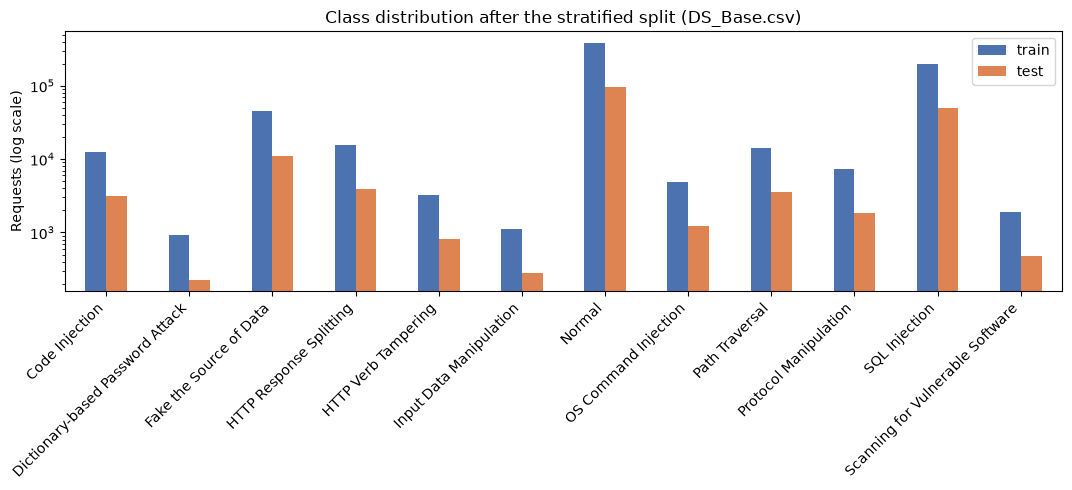

In [3]:
figure, axes = plt.subplots(figsize=(11, 5))
class_distribution.plot.bar(ax=axes, logy=True, color=["#4C72B0", "#DD8452"])
axes.set_title(f"Class distribution after the stratified split ({DATASET_NAME})")
axes.set_ylabel("Requests (log scale)")
axes.tick_params(axis="x", labelrotation=45)
plt.setp(axes.get_xticklabels(), ha="right")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "class-distribution.png", dpi=150)
plt.show()

## Encode the requests and build the model

In [4]:
def encode_requests_as_ascii_codes(request_texts: pd.Series, max_characters: int = SEQUENCE_MAX_CHARACTERS) -> np.ndarray:
    """ASCII code + 1 of the first `max_characters` characters, zero-padded; non-ASCII becomes '?'."""
    encoded_requests = np.zeros((len(request_texts), max_characters), np.uint8)
    for row_index, request_text in enumerate(request_texts):
        ascii_codes = np.frombuffer(request_text[:max_characters].encode("ascii", "replace"), np.uint8)
        encoded_requests[row_index, : len(ascii_codes)] = ascii_codes + 1
    return encoded_requests


class CnnBiLstmClassifier(nn.Module):
    """Character embedding -> Conv1d + ReLU + max-pool -> 2-layer BiLSTM -> linear classifier."""

    def __init__(self, class_count: int) -> None:
        super().__init__()
        self.character_embedding = nn.Embedding(CHARACTER_VOCABULARY_SIZE, CHARACTER_EMBEDDING_SIZE, padding_idx=0)
        self.convolution_block = nn.Sequential(
            nn.Conv1d(CHARACTER_EMBEDDING_SIZE, CONVOLUTION_FILTER_COUNT, CONVOLUTION_KERNEL_WIDTH,
                      padding=CONVOLUTION_KERNEL_WIDTH // 2),
            nn.ReLU(),
            nn.MaxPool1d(2),
        )
        self.bidirectional_lstm = nn.LSTM(CONVOLUTION_FILTER_COUNT, LSTM_HIDDEN_SIZE, num_layers=LSTM_LAYER_COUNT,
                                          bidirectional=True, batch_first=True)
        self.classification_head = nn.Linear(2 * LSTM_HIDDEN_SIZE, class_count)

    def forward(self, character_codes: torch.Tensor) -> torch.Tensor:
        embedded_sequence = self.character_embedding(character_codes.long())
        # Conv1d wants (batch, channels, length); the LSTM wants (batch, length, channels).
        convolved_sequence = self.convolution_block(embedded_sequence.transpose(1, 2)).transpose(1, 2)
        _, (final_hidden_states, _) = self.bidirectional_lstm(convolved_sequence)
        # The last layer's forward and backward final states.
        return self.classification_head(torch.cat([final_hidden_states[-2], final_hidden_states[-1]], dim=1))


@torch.no_grad()
def predict_in_batches(model: nn.Module, character_codes: torch.Tensor) -> np.ndarray:
    """Argmax class ids for every row, predicted in fixed-size batches to bound GPU memory."""
    model.eval()
    predicted_label_batches = [
        model(character_codes[batch_start : batch_start + PREDICTION_BATCH_SIZE]).argmax(dim=1).cpu()
        for batch_start in range(0, len(character_codes), PREDICTION_BATCH_SIZE)
    ]
    return torch.cat(predicted_label_batches).numpy()


train_character_codes = torch.from_numpy(encode_requests_as_ascii_codes(train_texts)).to(device)
test_character_codes = torch.from_numpy(encode_requests_as_ascii_codes(test_texts)).to(device)
train_label_tensor = torch.from_numpy(train_labels).to(device)
del train_texts, test_texts

cnn_bilstm_classifier = CnnBiLstmClassifier(len(class_names)).to(device)
class_weights = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=train_labels)
weighted_loss_function = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device))
optimizer = torch.optim.Adam(cnn_bilstm_classifier.parameters())
cnn_bilstm_classifier

CnnBiLstmClassifier(
  (character_embedding): Embedding(129, 100, padding_idx=0)
  (convolution_block): Sequential(
    (0): Conv1d(100, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bidirectional_lstm): LSTM(128, 64, num_layers=2, batch_first=True, bidirectional=True)
  (classification_head): Linear(in_features=128, out_features=12, bias=True)
)

## Train

In [5]:
# Test scores per epoch are recorded only for the training-curve graph; nothing is tuned on them.
training_history = []
train_sample_count = len(train_label_tensor)
steps_per_epoch = math.ceil(train_sample_count / TRAINING_BATCH_SIZE)
total_step_count = TRAINING_EPOCHS * steps_per_epoch
shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
training_start_time = last_log_time = time.monotonic()

for epoch_index in range(TRAINING_EPOCHS):
    cnn_bilstm_classifier.train()
    shuffled_indices = torch.randperm(train_sample_count, generator=shuffle_generator).to(device)
    epoch_loss_sum = torch.zeros((), device=device)  # Summed on the GPU to avoid a sync every step.
    for step_index in range(steps_per_epoch):
        batch_indices = shuffled_indices[step_index * TRAINING_BATCH_SIZE : (step_index + 1) * TRAINING_BATCH_SIZE]
        logits = cnn_bilstm_classifier(train_character_codes[batch_indices])
        batch_loss = weighted_loss_function(logits, train_label_tensor[batch_indices])
        optimizer.zero_grad(set_to_none=True)
        batch_loss.backward()
        optimizer.step()
        epoch_loss_sum += batch_loss.detach()
        if time.monotonic() - last_log_time < SECONDS_BETWEEN_PROGRESS_LOGS:
            continue
        completed_step_count = epoch_index * steps_per_epoch + step_index + 1
        minutes_remaining = (time.monotonic() - training_start_time) / completed_step_count * (total_step_count - completed_step_count) / 60
        log_progress(f"epoch {epoch_index + 1}/{TRAINING_EPOCHS} step {step_index + 1}/{steps_per_epoch} "
                     f"loss {batch_loss.item():.4f}, ~{minutes_remaining:.0f} min left")
        last_log_time = time.monotonic()

    epoch_predictions = predict_in_batches(cnn_bilstm_classifier, test_character_codes)
    if not math.isfinite(epoch_loss_sum.item()):
        raise FloatingPointError(f"training loss became {epoch_loss_sum.item()} in epoch {epoch_index + 1}")
    training_history.append({
        "epoch": epoch_index + 1,
        "train_loss": epoch_loss_sum.item() / steps_per_epoch,
        "test_accuracy": 100 * accuracy_score(test_labels, epoch_predictions),
        "test_macro_f1": 100 * f1_score(test_labels, epoch_predictions, average="macro", zero_division=0),
    })
    log_progress(f"finished epoch {epoch_index + 1}/{TRAINING_EPOCHS}: " + ", ".join(
        f"{key} {value:.4f}" for key, value in training_history[-1].items() if key != "epoch"))

training_minutes = (time.monotonic() - training_start_time) / 60
training_history = pd.DataFrame(training_history).set_index("epoch")
training_history

2026-11-18 17:32:08 [DS_Base.csv] finished epoch 1/5: train_loss 0.3719, test_accuracy 89.6165, test_macro_f1 74.0856


2026-11-18 17:32:18 [DS_Base.csv] epoch 2/5 step 1248/10742 loss 0.5031, ~3 min left


2026-11-18 17:33:09 [DS_Base.csv] finished epoch 2/5: train_loss 0.2750, test_accuracy 91.6688, test_macro_f1 74.1104


2026-11-18 17:33:18 [DS_Base.csv] epoch 3/5 step 2041/10742 loss 0.0527, ~3 min left


2026-11-18 17:34:18 [DS_Base.csv] epoch 3/5 step 9744/10742 loss 0.1671, ~2 min left


2026-11-18 17:34:30 [DS_Base.csv] finished epoch 3/5: train_loss 0.2621, test_accuracy 91.8049, test_macro_f1 75.6050


... (3 outputs left out)

2026-11-18 17:37:18 [DS_Base.csv] epoch 5/5 step 3020/10742 loss 0.3517, ~1 min left


2026-11-18 17:38:19 [DS_Base.csv] epoch 5/5 step 8159/10742 loss 0.0328, ~0 min left


2026-11-18 17:38:58 [DS_Base.csv] finished epoch 5/5: train_loss 0.2534, test_accuracy 93.0670, test_macro_f1 76.9926


,train_loss,test_accuracy,test_macro_f1
epoch,,,
1,0.371938,89.616488,74.085566
2,0.274979,91.668752,74.110402
3,0.262076,91.804910,75.605002
4,0.257067,92.258770,74.235448
5,0.253365,93.066991,76.992601


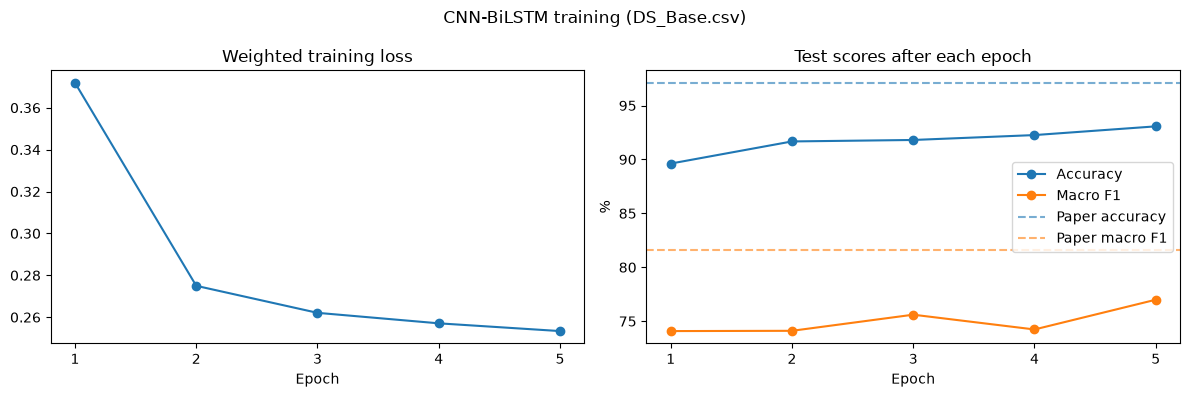

In [6]:
figure, (loss_axes, score_axes) = plt.subplots(1, 2, figsize=(12, 4))
loss_axes.plot(training_history.index, training_history["train_loss"], marker="o")
loss_axes.set_title("Weighted training loss")
loss_axes.set_xlabel("Epoch")
score_axes.plot(training_history.index, training_history["test_accuracy"], marker="o", label="Accuracy")
score_axes.plot(training_history.index, training_history["test_macro_f1"], marker="o", label="Macro F1")
score_axes.axhline(PAPER_ACCURACY, linestyle="--", color="C0", alpha=0.6, label="Paper accuracy")
score_axes.axhline(PAPER_MACRO_F1, linestyle="--", color="C1", alpha=0.6, label="Paper macro F1")
score_axes.set_title("Test scores after each epoch")
score_axes.set_xlabel("Epoch")
score_axes.set_ylabel("%")
score_axes.legend()
for axes in (loss_axes, score_axes):
    axes.set_xticks(training_history.index)
figure.suptitle(f"CNN-BiLSTM training ({DATASET_NAME})")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "training-history.png", dpi=150)
plt.show()

## Result: comparison with the paper

In [7]:
if torch.cuda.is_available():
    torch.cuda.synchronize()
inference_start_time = time.perf_counter()
predicted_labels = predict_in_batches(cnn_bilstm_classifier, test_character_codes)
inference_ms_per_request = 1000 * (time.perf_counter() - inference_start_time) / len(test_labels)

our_accuracy = 100 * accuracy_score(test_labels, predicted_labels)
our_macro_f1 = 100 * f1_score(test_labels, predicted_labels, average="macro", zero_division=0)
comparison_with_paper = pd.DataFrame(
    {"ours": [our_accuracy, our_macro_f1], "paper": [PAPER_ACCURACY, PAPER_MACRO_F1]},
    index=["accuracy", "macro_f1"],
)
comparison_with_paper["gap_points"] = comparison_with_paper["ours"] - comparison_with_paper["paper"]
comparison_with_paper["within_5_points"] = comparison_with_paper["gap_points"].abs() <= ALLOWED_GAP_PERCENTAGE_POINTS
replication_passed = bool(comparison_with_paper["within_5_points"].all())
log_progress(f"accuracy {our_accuracy:.2f}% (paper {PAPER_ACCURACY}%), macro F1 {our_macro_f1:.2f}% "
             f"(paper {PAPER_MACRO_F1}%), trained in {training_minutes:.1f} min, "
             f"{inference_ms_per_request:.4f} ms/request, within 5 points: {replication_passed}")
comparison_with_paper.round(2)

2026-11-18 17:39:04 [DS_Base.csv] accuracy 93.07% (paper 97.11%), macro F1 76.99% (paper 81.58%), trained in 7.7 min, 0.0331 ms/request, within 5 points: True


,ours,paper,gap_points,within_5_points
accuracy,93.07,97.11,-4.04,True
macro_f1,76.99,81.58,-4.59,True


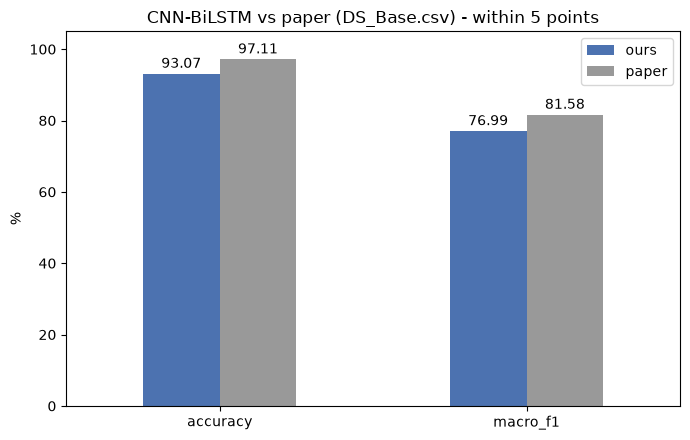

In [8]:
figure, axes = plt.subplots(figsize=(7, 4.5))
comparison_with_paper[["ours", "paper"]].plot.bar(ax=axes, rot=0, color=["#4C72B0", "#999999"])
for bar_container in axes.containers:
    axes.bar_label(bar_container, fmt="%.2f", padding=2)
axes.set_ylim(0, 105)
axes.set_ylabel("%")
axes.set_title(f"CNN-BiLSTM vs paper ({DATASET_NAME}) - "
               + ("within 5 points" if replication_passed else "NOT within 5 points"))
figure.tight_layout()
figure.savefig(RESULTS_DIR / "comparison-with-paper.png", dpi=150)
plt.show()

## Per-class scores

In [9]:
per_class_report = pd.DataFrame(classification_report(
    test_labels, predicted_labels, labels=np.arange(len(class_names)), target_names=class_names,
    digits=4, zero_division=0, output_dict=True,
)).T
per_class_report.round(4)

,precision,recall,f1-score,support
Code Injection,0.9886,0.9329,0.9600,3161.0000
Dictionary-based Password Attack,0.5586,0.9825,0.7122,228.0000
Fake the Source of Data,0.9740,0.9099,0.9409,11197.0000
HTTP Response Splitting,0.9940,0.9619,0.9777,3934.0000
HTTP Verb Tampering,0.9938,0.9938,0.9938,811.0000
Input Data Manipulation,0.0609,0.1011,0.0760,277.0000
Normal,0.9956,0.9223,0.9575,95335.0000
OS Command Injection,0.2315,0.8837,0.3669,1230.0000
Path Traversal,0.9926,0.9445,0.9680,3552.0000
Protocol Manipulation,0.1947,0.8979,0.3200,1831.0000


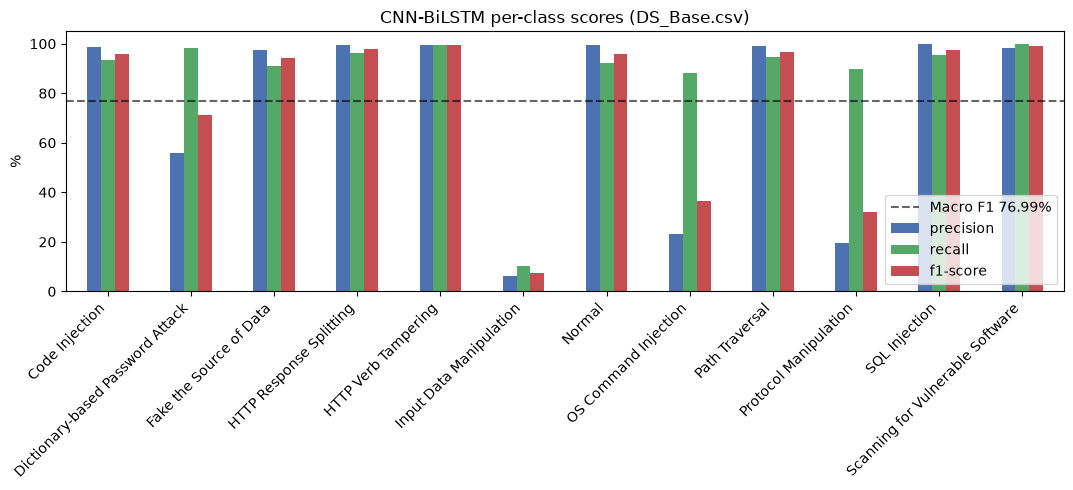

In [10]:
class_scores = per_class_report.loc[class_names, ["precision", "recall", "f1-score"]] * 100
figure, axes = plt.subplots(figsize=(11, 5))
class_scores.plot.bar(ax=axes, color=["#4C72B0", "#55A868", "#C44E52"])
axes.axhline(our_macro_f1, linestyle="--", color="black", alpha=0.6, label=f"Macro F1 {our_macro_f1:.2f}%")
axes.set_ylim(0, 105)
axes.set_ylabel("%")
axes.set_title(f"CNN-BiLSTM per-class scores ({DATASET_NAME})")
axes.legend(loc="lower right")
axes.tick_params(axis="x", labelrotation=45)
plt.setp(axes.get_xticklabels(), ha="right")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "per-class-scores.png", dpi=150)
plt.show()

## Confusion matrix

Rows are normalized, like Fig. 7 in the paper.

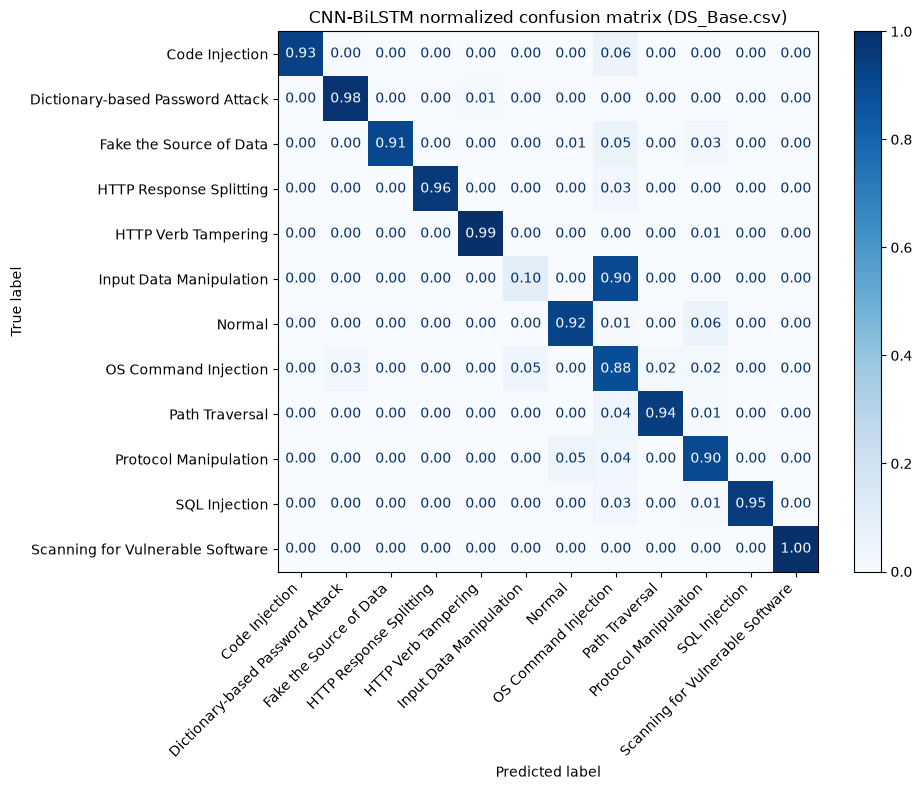

In [11]:
figure, axes = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    test_labels, predicted_labels, labels=np.arange(len(class_names)), display_labels=class_names,
    normalize="true", values_format=".2f", cmap="Blues", ax=axes, xticks_rotation=45,
)
plt.setp(axes.get_xticklabels(), ha="right")
axes.set_title(f"CNN-BiLSTM normalized confusion matrix ({DATASET_NAME})")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "confusion-matrix.png", dpi=150)
plt.show()

## Save the metrics

In [12]:
metrics_file = RESULTS_DIR / "metrics.json"
metrics = {
    "dataset": DATASET_NAME,
    "model": "CNN-BiLSTM",
    "device": str(device),
    "classes": class_names,
    "paper": {"accuracy": PAPER_ACCURACY, "macro_f1": PAPER_MACRO_F1},
    "ours": {"accuracy": our_accuracy, "macro_f1": our_macro_f1},
    "within_5_points": replication_passed,
    "training_minutes": training_minutes,
    "inference_ms_per_request": inference_ms_per_request,
    "training_history": training_history.reset_index().to_dict(orient="records"),
    "per_class_report": per_class_report.to_dict(orient="index"),
}
temporary_file = metrics_file.with_suffix(".json.tmp")  # Write then rename, so a crash can't leave half a file.
temporary_file.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
temporary_file.replace(metrics_file)
print("Saved:", metrics_file)
print("Graphs:", ", ".join(sorted(path.name for path in RESULTS_DIR.glob("*.png"))))

Saved: D:\Thesis\project-argus\results\ds-base\metrics.json
Graphs: class-distribution.png, comparison-with-paper.png, confusion-matrix.png, per-class-scores.png, training-history.png
